# TPC_Calibration: 反跳電子のエネルギー

アノード FADC ch とカソード FADC ch の組を「パネル」と呼びます(12 × 12 パネル、1 パネル = 32 × 32 ストリップ)。
反跳電子がどのパネルを通ったかを、エンコーダのヒット(ストリップ・クロック)の**アノード×カソード同時計数**で調べ、
そのパネルの較正係数で電荷をエネルギーに変換します。

0. (初期化時)パネルごとの較正係数 `a`, `b` を `Calibration20190130.dat` から読み、**両方に `Cal_Modify` を掛けておく**
1. 同じクロックでヒットしたアノードストリップとカソードストリップの組を数え、パネルごとのヒット数 `HitPanel` を作る
   (各パネルの端 4 本のストリップは除く)
2. `HitPanel > 100` のパネルだけを使う
3. 各アノード ch の電荷を、そのアノード ch が関わったパネルにヒット数の割合で振り分け、パネルごとの係数で変換して足す:
   $E_{\rm board} \mathrel{+}= (Q_{\rm anode} \times a + b) \times {\rm HitPanel}/\sum{\rm HitPanel}$
4. ボードごと(アノード 4 ch ずつ)に足したものを合計して `Ke` [keV]。合計がちょうど 0 なら無効

電荷はアノードだけを使います。CalcFADC で閾値を超えたサンプルがなかった ch の電荷 −80 も、
パネルにヒットがあればそのまま足されます(1 パネルあたり −1.5〜−3.3 keV 程度。参照と同じ扱い)。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `ParameterFile` | `param/20190528/Calibration20190130.dat` | パネルごとの較正係数 |
| `Cal_Modify` | 1.45305 | 全体の補正係数 |

> `setting.mac` には `Cal_Modify : 1.4530463` とありますが、参照ツール(haboc)は GUI の数値欄経由で値を受け取るため
> 有効数字 6 桁に丸められ、実際には 1.45305 が使われています。

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../../DataIO_example.ipynb) の「1. データのダウンロード」**を見てください。
1_DataIO の手順でデータを置いていれば、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節の手順でデータをコピーしてください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param/20190528


## 2. 生データツリーを作る

モジュールの出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。
処理の中身を確かめる図は、`ReadData → RawTreeWriter` で作る**生データツリー**(`RawTreeWriter/raw`)から描きます。
中身は `../8_RawTreeWriter/` を参照してください。ここでは Per02 の先頭 5000 イベントを使います。

ターミナル(コマンドプロンプト)では、リポジトリの `run_script` ディレクトリで次を実行するのと同じです。

```bash
cd EricaNext_try/run_script
python3 run_chain.py smile2p_20190701_Per02 -o Per02_raw_5000.root -n 5000 --raw --compression 505
```

| 引数 | 意味 |
|---|---|
| `smile2p_20190701_Per02` | 設定ファイル `config/smile2p_20190701_Per02.json`(データの場所と各モジュールのパラメータ) |
| `-o Per02_raw_5000.root` | 出力ファイル |
| `-n 5000` | 先頭 5000 イベントだけ処理する(省略すると全イベント) |
| `--raw` | `ReadData → RawTreeWriter` だけを実行し、生データツリーを書く(再構成はしない) |
| `--compression 505` | ROOT の圧縮を zstd(レベル 5)にする。既定の圧縮より約 2 割小さくなる |

下のセルは同じコマンドを Python から実行しています(`sys.executable` は今のカーネルの python3、
`RUN_CHAIN` は `run_chain.py` のパス、`CONFIG` は設定名)。出力が既にあれば再実行しません。

In [3]:
# ReadData -> RawTreeWriter だけを実行して生データツリーを作る(先頭 5000 イベント、zstd 圧縮)
RAW = CACHE / "Per02_raw_5000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(RAW), "-n", "5000", "--raw", "--compression", "505"]
print(" ".join(cmd))
if not RAW.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

# ボード ID の一覧(別ツリー run_info に 1 行だけ入っている)
info = ROOT.RDataFrame("RawTreeWriter/run_info", str(RAW)).AsNumpy(["anode_ids", "cathode_ids", "ha_ids"])
HA_IDS = [int(x) for x in info["ha_ids"][0]]
print("HA modules:", HA_IDS)

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials/cache/Per02_raw_5000.root -n 5000 --raw --compression 505


HA modules: [1, 2, 3, 7, 8, 9, 13, 14, 15, 19, 20, 21, 25, 26, 27, 31, 32, 33]


## 3. アノード×カソード同時計数

生データツリーのヒットから、同じクロックでヒットしたアノードとカソードのストリップの組を数えます。
全イベントで積算すると、TPC を上から見た像になります。TPC_Calibration はこれをイベントごとに
パネル(32 × 32 ストリップ)単位にまとめた `HitPanel` を使います。

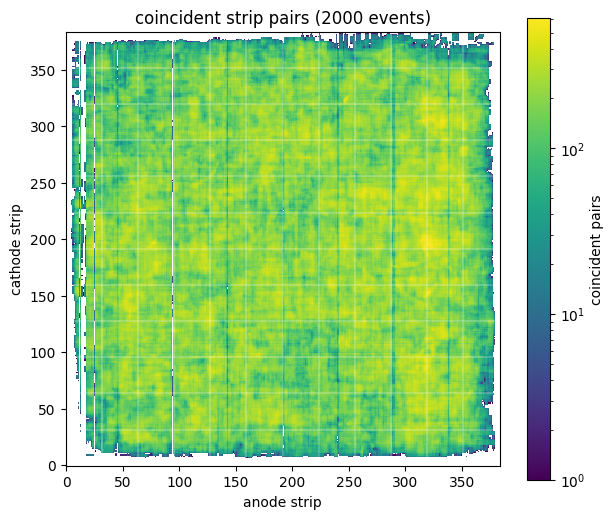

In [4]:
img = np.zeros((384, 384))
d = ROOT.RDataFrame("RawTreeWriter/raw", str(RAW)).Range(2000).AsNumpy(
    ["hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock"])
for sa, ca, sc, cc in zip(d["hit_a_strip"], d["hit_a_clock"], d["hit_c_strip"], d["hit_c_clock"]):
    sa, ca, sc, cc = (np.asarray(x) for x in (sa, ca, sc, cc))
    pairs_a, pairs_c = [], []
    for clk in np.intersect1d(ca, cc):
        a, c = sa[ca == clk], sc[cc == clk]
        pairs_a.append(np.repeat(a, len(c))); pairs_c.append(np.tile(c, len(a)))
    if pairs_a:
        pa, pc = np.concatenate(pairs_a), np.concatenate(pairs_c)
        np.add.at(img, (pa, pc), 1)

fig, ax = plt.subplots(figsize=(7, 6))
m = ax.pcolormesh(np.arange(385) - 0.5, np.arange(385) - 0.5, np.where(img > 0, img, np.nan).T, norm="log")
ax.set_aspect("equal"); fig.colorbar(m, ax=ax, label="coincident pairs")
for b in range(0, 385, 32):   # パネル(FADC ch)の境界
    ax.axvline(b - 0.5, color="w", lw=0.3); ax.axhline(b - 0.5, color="w", lw=0.3)
ax.set_xlabel("anode strip"); ax.set_ylabel("cathode strip"); ax.set_title("coincident strip pairs (2000 events)")
plt.show()

## 4. TPC のエネルギースペクトル

TPC_Calibration が求めた `Ke` は再構成ツリー `single_hit` に入っています(シングルヒットとして再構成できた `err_flag == 0` の行)。

全チェーンを先頭 50000 イベントで実行し、再構成ツリー `Reconstruct/single_hit` の `err_flag == 0` の行を読みます。

ターミナル(コマンドプロンプト)では、リポジトリの `run_script` ディレクトリで次を実行するのと同じです。

```bash
cd EricaNext_try/run_script
python3 run_chain.py smile2p_20190701_Per02 -o Per02_50000.root -n 50000
```

| 引数 | 意味 |
|---|---|
| `smile2p_20190701_Per02` | 設定ファイル `config/smile2p_20190701_Per02.json`(データの場所と各モジュールのパラメータ) |
| `-o Per02_50000.root` | 出力ファイル |
| `-n 50000` | 先頭 50000 イベントだけ処理する(省略すると全イベント、約 1 時間) |

下のセルは同じコマンドを Python から実行しています(`sys.executable` は今のカーネルの python3、
`RUN_CHAIN` は `run_chain.py` のパス、`CONFIG` は設定名)。出力は `tutorials/cache/` に置き、
既にあれば再実行しません(他のノートブックと共有)。

In [5]:
OUT = CACHE / "Per02_50000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(OUT), "-n", "50000"]
print(" ".join(cmd))
if not OUT.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials/cache/Per02_50000.root -n 50000


In [6]:
d = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT)).Filter("err_flag == 0").AsNumpy(['err_flag', 'Ke'])
ev = {k: (vec(v) if v.dtype == object else v) for k, v in d.items()}   # 配列型の列は 2 次元配列に
print("err_flag == 0:", len(ev["err_flag"]))

err_flag == 0: 26697


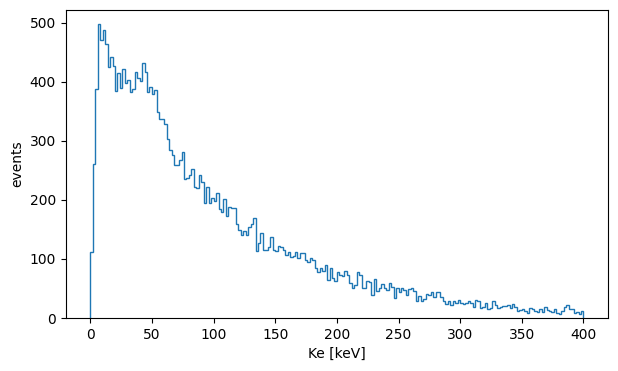

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ev["Ke"], bins=200, range=(0, 400), histtype="step")
ax.set_xlabel("Ke [keV]"); ax.set_ylabel("events")
plt.show()